# <font color=DodgerBlue>Rahnema College ML Bootcamp Challenge</font>
### M. Mahdi Mostafaei

______________

##  <font color=DodgerBlue >Task A:</font>  kNN Classifier

Importing needed Libaries:

In [1]:
import numpy as np
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split


from collections import Counter
import matplotlib.pyplot as plt

Loading & splitting wine dataset as challenge insrtuctions:

In [2]:
# Load the dataset
X, y = load_wine(return_X_y=True)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

### Algorithm

We Compute **Euclidean distance** of each $x_t \in X_{test}$ from all points in $X_{train}$:

$d(\mathbf{x}_{i}, \mathbf{x'}_{i}) = \sqrt{\sum_{i=1}^{n} (x_i - x'_{i})^2}$

Which is a special form $(p=2)$ of the general **Minkowski Distance**:

$d(\mathbf{x}_i, \mathbf{x'}_{i}) = \left( \sum_{i=1}^{n} |x_i - x'_i|^p \right)^{1/p}$

In [3]:
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

def predict_knn(X_train, y_train, X_test, k=3):
    predictions = []
    
    for x_t in X_test:
        # Calculate distances between x_t and all examples in X_train
        distances = [euclidean_distance(x_t, x_tr) for x_tr in X_train]
        
        # Get the indices of the k nearest samples
        k_indices = np.argsort(distances)[:k]
        
        # Extract the labels of those k nearest neighbor samples
        k_nearest_labels = [y_train[i] for i in k_indices]
        
        # Predict the most common class label (Majority Vote)
        most_common = Counter(k_nearest_labels).most_common(1)
        predictions.append(most_common[0][0])
        
    return np.array(predictions)

# Compute accuracy as correct predicted labels to all true labels
def accuracy(y_true, y_pred):
    return np.sum(y_true == y_pred) / len(y_true)

### Prediction & Results

Making prediction and computing accuracies for different k values.

We use odd k values to prevent a tie in the *Majority Vote* step of the prediction.

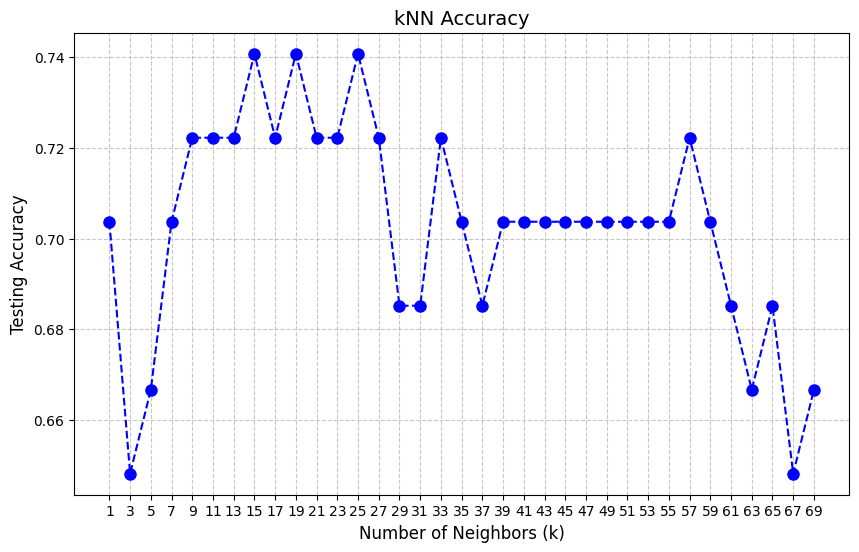

In [4]:
odd_k_values = range(1, 70, 2)
accuracies = []

# Loop through each odd k, make predictions, and calculate accuracy
for k in odd_k_values:
    predictions = predict_knn(X_train, y_train, X_test, k=k)
    acc = accuracy(y_test, predictions)
    accuracies.append(acc)

# Plotting the Results
plt.figure(figsize=(10, 6))
plt.plot(odd_k_values, accuracies, marker='o', linestyle='dashed', color='b', markersize=8)

# Formatting the chart for readability
plt.title('kNN Accuracy', fontsize=14)
plt.xlabel('Number of Neighbors (k)', fontsize=12)
plt.ylabel('Testing Accuracy', fontsize=12)
plt.xticks(odd_k_values) # Force the x-axis to show our specific odd numbers
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Standardization for More Accuracy
I expected higher accuracies. After consulting with Gemini, he suggested that this is o probably due to fact that the Wine dataset contains 13 features on vastly different scales, but the Eucleadian distance treats all numbers equally. Therefore I used Z-score normalization to fix this unbalancedness:

$z = \frac{x - \mu }{\sigma}$ where $\mu$ is the mean of dataset and $\mu$ is its stamdard deviation.

In [5]:
# Standard Scaling
train_mean = np.mean(X_train, axis=0)
train_std = np.std(X_train, axis=0)

X_train_scaled = (X_train - train_mean) / train_std
X_test_scaled = (X_test - train_mean) / train_std

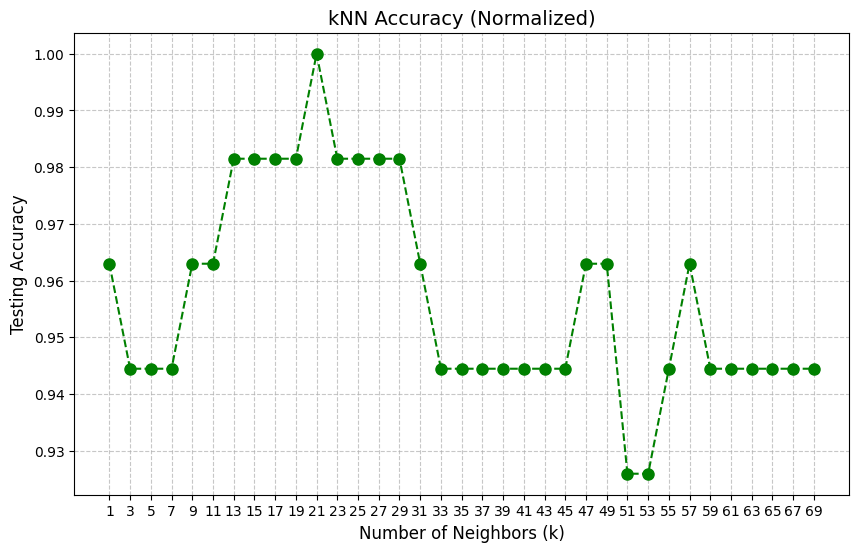

In [6]:
odd_k_values = range(1, 70, 2)
accuracies_scaled = []


for k in odd_k_values:
    predictions = predict_knn(X_train_scaled, y_train, X_test_scaled, k=k)
    acc = accuracy(y_test, predictions)
    accuracies_scaled.append(acc)

# Plotting the Results
plt.figure(figsize=(10, 6))
plt.plot(odd_k_values, accuracies_scaled, marker='o', linestyle='dashed', color='g', markersize=8)

plt.title('kNN Accuracy (Normalized)', fontsize=14)
plt.xlabel('Number of Neighbors (k)', fontsize=12)
plt.ylabel('Testing Accuracy', fontsize=12)
plt.xticks(odd_k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Sanity Check via SKLearn

Comparing my results with scikit-learn’s `KNeighborsClassifier` outputs:

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score


odd_k_values = range(1, 70, 2)
sklearn_accuracies = []


for k in odd_k_values:
    # Initialize the model with Euclidean distance (p=2)
    knn_sklearn = KNeighborsClassifier(n_neighbors=k, p=2)
    
    # Fit the model using the scaled training data
    knn_sklearn.fit(X_train_scaled, y_train)
    
    # Predict on the scaled test data
    y_pred = knn_sklearn.predict(X_test_scaled)
    
    # Calculate the accuracy
    acc = accuracy_score(y_test, y_pred)
    sklearn_accuracies.append(acc)

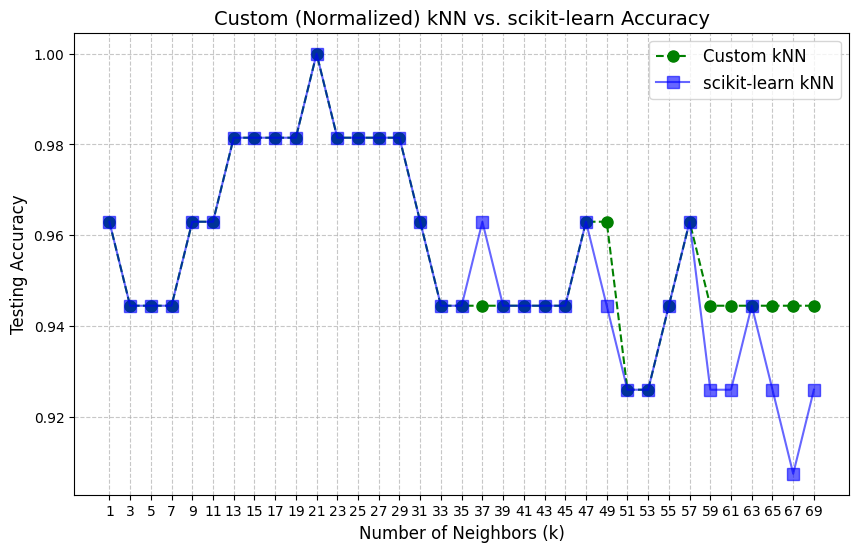

In [8]:
plt.figure(figsize=(10, 6))
plt.plot(odd_k_values, accuracies_scaled, marker='o', linestyle='dashed', color='g', 
         markersize=8, label='Custom kNN')
plt.plot(odd_k_values, sklearn_accuracies, marker='s', linestyle='-', color='b', 
         markersize=8, alpha=0.6, label='scikit-learn kNN')

# Formatting the chart
plt.title('Custom (Normalized) kNN vs. scikit-learn Accuracy', fontsize=14)
plt.xlabel('Number of Neighbors (k)', fontsize=12)
plt.ylabel('Testing Accuracy', fontsize=12)
plt.xticks(odd_k_values)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(loc='upper right', fontsize=12)
plt.show()